In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
from scipy import linalg, optimize, stats
import matplotlib.pyplot as plt
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080206
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

info_str = f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}"
MACHINE_FP = hashlib.sha256(info_str.encode()).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]      {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] C:\Users\111\anaconda3
[学号]      20244080206
[机器指纹] ac2d7ea75d74ffb2
[RUN_ID]   20244080206-ac2d7ea75d74ffb2


实验1：NumPy 数组、数据类型与索引

In [2]:
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False
np.random.seed(42) #固定随机种子

In [3]:
#1 创建int,float,bool ndarray，输出dtype shape ndim
arr_int = np.array([1,2,3], dtype=int)
arr_float = np.array([1.1, 2.2, 3.3])
arr_bool = np.array([True, False, True])

for arr,name in zip([arr_int,arr_float,arr_bool],["int数组","float数组","bool数组"]):
    print(f"==== {name} ====")
    print(f"dtype:{arr.dtype}, shape:{arr.shape}, ndim:{arr.ndim}")

#2 np.arange(12) reshape (3,4)、(2,3,2)
a1 = np.arange(12)
a2 = a1.reshape(3,4)
a3 = a1.reshape(2,3,2)
print("\na1:",a1)
print("\na2 shape(3,4):\n", a2)
print("\na3 shape(2,3,2):\n", a3)
print("改变形状，元素总个数必须不变，总元素 = shape各维度乘积")

#3 (3,4)数组索引：第2行；1~3列；大于6的元素
mat34 = np.arange(12).reshape(3,4)
row2 = mat34[1,:]
col1_3 = mat34[:,1:4]
gt6 = mat34[mat34>6]
print("\n原矩阵mat34\n",mat34)
print("第2行：", row2, "shape", row2.shape)
print("第1~3列\n", col1_3, "shape", col1_3.shape)
print("大于6元素：", gt6, "shape", gt6.shape)

#4 np.arange(10)：小于2或大于7；大于3且小于7
ar10 = np.arange(10)
sel1 = ar10[(ar10 <2) | (ar10>7)]
sel2 = ar10[(ar10>3) & (ar10<7)]
print("\n小于2或大于7：", sel1)
print("大于3且小于7：", sel2)

#5 (2,2)数组对比 * multiply @ matmul
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
#multiply是逐元素对应相乘； matmul为数学矩阵乘法
print("\nA*B逐元素乘法\n", A*B)
print("np.multiply(A,B)\n", np.multiply(A,B))
print("@矩阵乘法\n", A@B)
print("np.matmul(A,B)\n", np.matmul(A,B))


==== int数组 ====
dtype:int64, shape:(3,), ndim:1
==== float数组 ====
dtype:float64, shape:(3,), ndim:1
==== bool数组 ====
dtype:bool, shape:(3,), ndim:1

a1: [ 0  1  2  3  4  5  6  7  8  9 10 11]

a2 shape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

a3 shape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
改变形状，元素总个数必须不变，总元素 = shape各维度乘积

原矩阵mat34
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
第2行： [4 5 6 7] shape (4,)
第1~3列
 [[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]] shape (3, 3)
大于6元素： [ 7  8  9 10 11] shape (5,)

小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]

A*B逐元素乘法
 [[ 5 12]
 [21 32]]
np.multiply(A,B)
 [[ 5 12]
 [21 32]]
@矩阵乘法
 [[19 22]
 [43 50]]
np.matmul(A,B)
 [[19 22]
 [43 50]]


实验2：随机抽样、统计与缺失值

In [4]:
#1 1000个均值70标准差10；clip限制0‑100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数", len(scores))
print(f"min:{scores.min():.2f}, max:{scores.max():.2f}, mean:{scores.mean():.2f}, std:{scores.std():.2f}, 极差:{scores.max()-scores.min():.2f}")

#2 arange(1‑11)不放回抽5个；均匀抽样 & 加权抽样
pop = np.arange(1,11)
sample_uniform = np.random.choice(pop, size=5, replace=False)
sample_weighted = np.random.choice(pop, size=5, replace=False, p=pop/np.sum(pop))
print("\n均匀抽样：", sample_uniform)
print("按数值大小加权抽样：", sample_weighted)

#3 random.permutation(不改变原数组) vs np.random.shuffle原地打乱
orig = np.array([1,2,3,4,5])
arr_perm = np.random.permutation(orig)
print("\npermutation后原数组不变 orig=", orig, "perm结果", arr_perm)

orig2 = np.array([1,2,3,4,5])
np.random.shuffle(orig2)
print("shuffle原地打乱 orig2=", orig2)

#4 设置nan；普通均值 vs nanmean；统计nan数量
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan
mean_raw = np.mean(scores_nan)
mean_nan = np.nanmean(scores_nan)
nan_cnt = np.sum(np.isnan(scores_nan))
print(f"\n普通np.mean含nan得到 {mean_raw}；np.nanmean忽略nan得到 {mean_nan:.3f}；缺失值数量：{nan_cnt}")
print("说明：普通mean遇到nan结果直接nan，必须用nanmean跳过缺失值")

#5 成绩+序号，内存表格，不写磁盘
df_exp2 = pd.DataFrame({"score":scores_nan, "idx":np.arange(len(scores_nan))})


样本数 1000
min:37.59, max:100.00, mean:70.18, std:9.76, 极差:62.41

均匀抽样： [ 4  9  2  6 10]
按数值大小加权抽样： [10  2  8  9  6]

permutation后原数组不变 orig= [1 2 3 4 5] perm结果 [5 1 3 2 4]
shuffle原地打乱 orig2= [1 5 2 4 3]

普通np.mean含nan得到 nan；np.nanmean忽略nan得到 70.196；缺失值数量：3
说明：普通mean遇到nan结果直接nan，必须用nanmean跳过缺失值


实验 3: SciPy 数值计算 + Matplotlib 可视化

线性方程组解 x=2.0, y=3.0
代入验证 M@sol = [35 25]

正根求解成功 True [1.41421356] f值 [4.4408921e-16]
负根求解成功 True [-1.41421356] f值 [4.4408921e-16]

极小点x [-0.50000001] 函数值 1.75

t‑test t统计量=-7.7861, p‑value=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


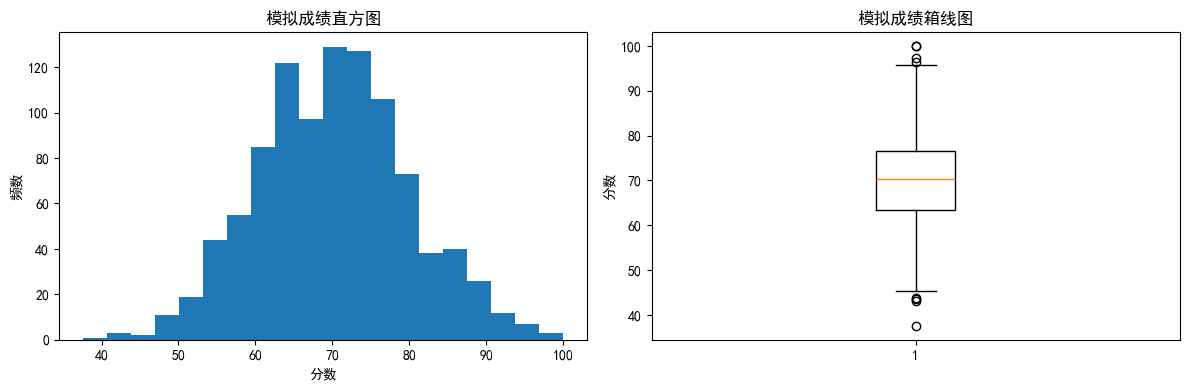

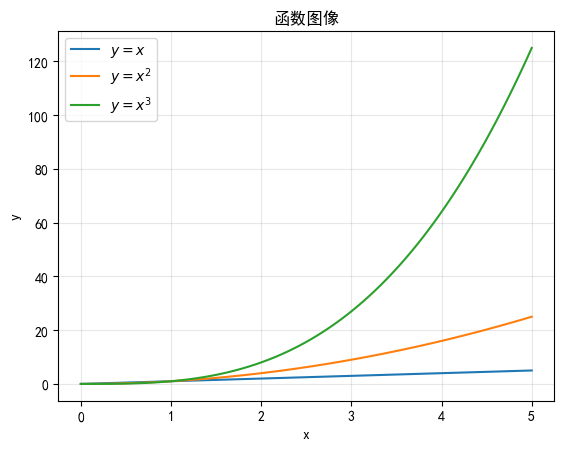

In [5]:
#1 解方程组 3x+y=9；x+2y=8
M = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = linalg.solve(M, b)
print(f"线性方程组解 x={sol[0]}, y={sol[1]}")
print("代入验证 M@sol =", M@b)

#2 scipy.optimize.root求 x²‑2=0正负根
def f(x):
    return x**2 - 2
res_pos = optimize.root(f, x0=1.5)
res_neg = optimize.root(f, x0=-1.5)
print("\n正根求解成功", res_pos.success, res_pos.x, "f值", f(res_pos.x))
print("负根求解成功", res_neg.success, res_neg.x, "f值", f(res_neg.x))

#3 minimize f(x)=x²+x+2最小值
def func_min(x):
    return x[0]**2 + x[0] + 2
res_min = optimize.minimize(func_min, x0=0)
print("\n极小点x", res_min.x, "函数值", res_min.fun)

#4 t检验，两组正态样本
s1 = stats.norm.rvs(loc=0, scale=1, size=100, random_state=42)
s2 = stats.norm.rvs(loc=1, scale=1, size=100, random_state=42)
t_stat, p_val = stats.ttest_ind(s1, s2)
print(f"\nt‑test t统计量={t_stat:.4f}, p‑value={p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p<{alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p≥{alpha}，不能拒绝原假设，无显著差异")

#5 绘图：有效成绩直方图+箱线图；y=x, x², x³在0~5折线
valid_scores = scores[~np.isnan(scores)]

plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.hist(valid_scores, bins=20)
plt.title("模拟成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,2,2)
plt.boxplot(valid_scores)
plt.title("模拟成绩箱线图")
plt.ylabel("分数")
plt.tight_layout()
plt.show()

x_line = np.linspace(0, 5, 100)
y1 = x_line
y2 = x_line**2
y3 = x_line**3
plt.figure()
plt.plot(x_line,y1, label="$y=x$")
plt.plot(x_line,y2, label="$y=x^2$")
plt.plot(x_line,y3, label="$y=x^3$")
plt.title("函数图像")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


实验4：pandas Series、DataFrame与内存中的CSV读写

In [6]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")

#1 Total总分 Average平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3
print("行索引：",df.index.tolist())
print("列名：",df.columns.tolist())
print("\n前3行")
print(df.head(3))
print("\n统计信息")
print(df.describe())

#2 loc iloc读取Carol；筛选平均分>=80
print("\n==== Carol记录 ====")
print(df.loc["Carol"])
# Carol是第2号索引（0开始）
print(df.iloc[2])
high_avg = df[df["Average"] >= 80]
print("\n平均分>=80学生")
print(high_avg)

#3 axis=0列均值，axis=1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n各科列均值(axis=0)")
print(col_mean)
print("\n每个学生行均值(axis=1)")
print(row_mean)

#4 apply求每行最高分；agg求每科min mean max；rank排名
df["max_score"] = df[["Math","English","Python"]].apply(max, axis=1)
stat_agg = df[["Math","English","Python"]].agg(["min","mean","max"])
df["Math_rank"] = df["Math"].rank(ascending=False)
print("\n每行最高分")
print(df["max_score"])
print("\nagg统计每科min mean max")
print(stat_agg)
print("\nMath排名")
print(df[["Math","Math_rank"]])

#5 group分组统计；transform增加组内Python平均分
grouped = df.groupby("Group")
print("\n分组每组人数，三科平均分")
print(grouped.agg({"Math":"mean","English":"mean","Python":"mean","Average":"mean"}))
print(grouped.size())
df["Group_Python_mean"] = grouped["Python"].transform("mean")
print("\n增加组Python平均分列")
print(df[["Group","Python","Group_Python_mean"]])

#6 filter保留组Python平均分>=80
group_filtered = grouped.filter(lambda g: g["Python"].mean() >= 80)
print("\nfilter过滤组Python>=80")
print(group_filtered)

#7 协方差矩阵、皮尔森相关系数
subj = df[["Math","English","Python"]]
cov_mat = subj.cov()
corr_mat = subj.corr()
print("\n协方差矩阵")
print(cov_mat)
print("\n皮尔森相关系数矩阵")
print(corr_mat)
print("解释示例：Math与Python相关系数，正数说明正相关；绝对值越接近1相关性越强，接近0线性相关性弱")


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

统计信息
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

==== Carol记录 ====
Group              B
Math   